# Proyecto OSITRAN: análisis de accidentes de tránsito

**Archivos requeridos en la misma carpeta:** `202603-PDE-REP-00204.csv`, `DEPARTAMENTOS_LIMITES.zip`, `red_vial_nacional.zip` y `ne_110m_admin_0_countries.zip`.

**Nota metodológica:** se conserva la regla de excluir rutas con “SIN” y códigos completamente numéricos. Conviene justificar esta decisión en el informe, porque podría excluir registros útiles.

In [8]:
from pathlib import Path
import zipfile
import re
import unicodedata

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from shapely.geometry import box

ARCHIVO_CSV = Path("202603-PDE-REP-00204.csv")
ARCHIVO_DEPARTAMENTOS = Path("DEPARTAMENTOS_LIMITES.zip")
ARCHIVO_RED_VIAL = Path("red_vial_nacional.zip")
ARCHIVO_PAISES = Path("ne_110m_admin_0_countries.zip")

CRS_MAPA = "EPSG:4326"
XMIN, XMAX = -82.5, -67.0
YMIN, YMAX = -19.5, 1.5
COLOR_OCEANO = "#DCEEF7"

NOMBRES_RUTAS = {
    "PE1N": "Panamericana Norte / Costa Norte",
    "PE1S": "Panamericana Sur / Costa Sur",
    "PE3N": "Longitudinal de la Sierra Norte",
    "PE3S": "Longitudinal de la Sierra Sur",
    "PE5N": "Longitudinal de la Selva Norte",
    "PE5S": "Longitudinal de la Selva Sur",
    "PE10A": "Ruta nacional PE10A",
    "PE022": "Ruta nacional PE022",
    "PE30C": "Ruta nacional PE30C",
    "PE34A": "Ruta nacional PE34A",
    "PE34B": "Ruta nacional PE34B",
    "PE30A": "Ruta nacional PE30A",
    "PE03": "Ruta nacional PE03",
    "PE08": "Ruta nacional PE08",
}

def normalizar_ruta(valor):
    # Unifica códigos eliminando espacios, tildes y signos.
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor).strip().upper())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^A-Z0-9]", "", texto)

def normalizar_nombre(valor):
    texto = unicodedata.normalize("NFKD", str(valor).strip().lower())
    return "".join(c for c in texto if not unicodedata.combining(c))

## 1. Carga y limpieza del dataset

In [9]:
if not ARCHIVO_CSV.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {ARCHIVO_CSV}")

df_original = pd.read_csv(ARCHIVO_CSV, sep=";", encoding="utf-8")
total_original = len(df_original)
duplicados = int(df_original.duplicated().sum())

print(f"Registros originales: {total_original:,}")
print(f"Duplicados exactos: {duplicados:,} ({duplicados / total_original * 100:.2f}%)")

df = df_original.drop_duplicates().copy()

ruta_texto = df["RUTA"].astype("string").str.strip()
mascara_sin = ruta_texto.str.contains("SIN", case=False, na=False, regex=False)
mascara_numerica = ruta_texto.str.fullmatch(r"\d+(?:\.\d+)?", na=False)

print("Filas con ruta que contiene 'SIN':", int(mascara_sin.sum()))
print("Filas con ruta numérica:", int((~mascara_sin & mascara_numerica).sum()))

df = df.loc[~(mascara_sin | mascara_numerica)].reset_index(drop=True)
df["RUTA_NORMALIZADA"] = df["RUTA"].apply(normalizar_ruta)
df["CANTIDAD ACCIDENTES"] = pd.to_numeric(
    df["CANTIDAD ACCIDENTES"], errors="coerce"
).fillna(0)

print(f"Registros después de la limpieza: {len(df):,}")
df.to_csv("OSITRAN_limpio.csv", index=False, encoding="utf-8-sig")
display(df.head())

Registros originales: 41,833
Duplicados exactos: 3,488 (8.34%)
Filas con ruta que contiene 'SIN': 14242
Filas con ruta numérica: 53
Registros después de la limpieza: 24,050


,ANIO,MES,ENTIDAD_PRESTADORA,CONCESION,SIGLAS,TIPO_ACCIDENTE,CAUSA_ACCIDENTE,TIPO_TRANSPORTE,TIPO_VEHICULO,CLIMA,TIPO_VIA,RUTA,TRAMO,CANTIDAD VEHINVOLUCRADOS,CANTIDAD AFECTADOS,CANTIDAD ACCIDENTES,RUTA_NORMALIZADA
0,2022,1,DESARROLLO VIAL DE LOS ANDES S.A.C.,IIRSA Centro Tramo 2: Puente Ricardo Palma - L...,IC2,DESPISTE Y VOLCADURA,INVASIÓN CARRIL; EXCESO DE VELOCIDAD,PARTICULAR,CAMIONETA,SOLEADO,CARRETERA,PE022,LIMA-OROYA,1,3,1,PE022
1,2022,1,CONCESIONARIA VIAL DEL PERÚ S.A.,Red Vial 6: Tramo Vial Puente Pucusana - Cerro...,RV6,DESPISTE Y VOLCADURA,EXCESO DE VELOCIDAD,PRIVADO DE PASAJEROS,CAMIONETA,SOLEADO,AUTOPISTA,PE-1S,CHINCHA/ICA,1,1,1,PE1S
2,2022,1,CONCESIONARIA VIAL DEL PERÚ S.A.,Red Vial 6: Tramo Vial Puente Pucusana - Cerro...,RV6,DESPISTE Y VOLCADURA,EXCESO DE VELOCIDAD,PRIVADO DE PASAJEROS,AUTOMOVIL,SOLEADO,AUTOPISTA,PE-1S,Ica/Ica,1,4,1,PE1S
3,2022,1,CONCESIONARIA VIAL DEL PERÚ S.A.,Red Vial 6: Tramo Vial Puente Pucusana - Cerro...,RV6,DESPISTE Y VOLCADURA,EXCESO DE VELOCIDAD,PRIVADO DE PASAJEROS,AUTOMOVIL,SOLEADO,AUTOPISTA,PE-1S,Ica/Ica,1,1,1,PE1S
4,2022,1,CONCESIONARIA VIAL DEL PERÚ S.A.,Red Vial 6: Tramo Vial Puente Pucusana - Cerro...,RV6,DESPISTE Y VOLCADURA,DESPISTE,PRIVADO DE PASAJEROS,AUTOMOVIL,SOLEADO,AUTOPISTA,PE-1S,Ica/Ica,1,1,1,PE1S


## 2. Carga de las capas geográficas

In [10]:
archivos_zip = {
    "departamentos": ARCHIVO_DEPARTAMENTOS,
    "red_vial": ARCHIVO_RED_VIAL,
    "paises": ARCHIVO_PAISES,
}
carpetas = {
    "departamentos": Path("datos_departamentos"),
    "red_vial": Path("datos_red_vial"),
    "paises": Path("datos_paises"),
}

for clave, archivo_zip in archivos_zip.items():
    if not archivo_zip.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {archivo_zip}")
    carpetas[clave].mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archivo_zip, "r") as zf:
        zf.extractall(carpetas[clave])

def buscar_shapefile(carpeta):
    encontrados = list(carpeta.rglob("*.shp"))
    if not encontrados:
        raise FileNotFoundError(f"No se encontró shapefile en {carpeta}")
    return encontrados[0]

departamentos = gpd.read_file(buscar_shapefile(carpetas["departamentos"]))
capa_vial = gpd.read_file(buscar_shapefile(carpetas["red_vial"]))
paises = gpd.read_file(buscar_shapefile(carpetas["paises"]))

for nombre, capa in [("departamentos", departamentos), ("capa_vial", capa_vial), ("paises", paises)]:
    if capa.crs is None:
        raise ValueError(f"La capa {nombre} no tiene CRS definido.")

print("CRS de la red vial:", capa_vial.crs)
print("Columnas de la red vial:", capa_vial.columns.tolist())
print("Columnas de países:", paises.columns.tolist())

CRS de la red vial: EPSG:4326
Columnas de la red vial: ['OBJECTID', 'cCodRuta', 'dLongitud', 'cSentido', 'cSuperfici', 'RST_LBL', 'DATA', 'FECHA_ACT', 'BASE', 'IDDPTO', 'NOMBDEP', 'IDPROV', 'NOMBPROV', 'IDDIST', 'NOMBDIST', 'Trayectori', 'Cambios', 'RUTA', 'Notas', 'MOD_EJE', 'ID', 'ESTADO', 'Long_3D', 'Distrito', 'Cod_Dist', 'Provincia', 'Cod_Prov', 'Departamen', 'Cod_Dep', 'Ubig_unido', 'Sentido', 'Fecha_GPS', 'Tipo_Super', 'Tramo', 'Long_Km', 'RECLASIF', 'CAT_VIAL', 'COD_CATG', 'geometry']
Columnas de países: ['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 

## 3. Accidentes reportados por ruta

In [11]:
columnas_requeridas = {"RUTA_NORMALIZADA", "CANTIDAD ACCIDENTES"}
faltantes = columnas_requeridas - set(df.columns)
if faltantes:
    raise KeyError(f"Faltan columnas requeridas: {sorted(faltantes)}")

# Se suman los accidentes reportados; no se cuenta simplemente el número de filas.
accidentes_ruta = (
    df.loc[df["RUTA_NORMALIZADA"] != ""]
      .groupby("RUTA_NORMALIZADA", as_index=False)["CANTIDAD ACCIDENTES"]
      .sum()
      .rename(columns={"CANTIDAD ACCIDENTES": "TOTAL_ACCIDENTES"})
      .sort_values("TOTAL_ACCIDENTES", ascending=False)
      .reset_index(drop=True)
)

display(accidentes_ruta.head(15))

,RUTA_NORMALIZADA,TOTAL_ACCIDENTES
0,PE1N,4591
1,PE1S,3742
2,PE022,3381
3,PE3N,1357
4,PE30C,1320
5,PE10A,1114
6,PE34A,1088
7,PE5N,1059
8,PE03,876
9,PE34B,815


## 4. Densidad de accidentes por longitud (exploratorio)

Este indicador divide el total de accidentes entre la longitud de las geometrías viales asociadas a cada ruta. No es una tasa definitiva de riesgo: se debe validar que las geometrías del MTC cubran la ruta completa y no contengan segmentos duplicados. Tampoco incorpora el volumen de tránsito.

,RUTA_NORMALIZADA,TOTAL_ACCIDENTES,LONGITUD_KM,ACCIDENTES_POR_100_KM
10,PE30A,776,444.344461,174.639288
0,PE1N,4591,2621.305811,175.141717
16,PE5NB,236,126.831377,186.073829
4,PE30C,1320,656.229976,201.148995
9,PE34B,815,353.780018,230.369144
18,PE04B,212,60.759688,348.915551
6,PE34A,1088,299.880732,362.810906
11,PE08,696,179.147866,388.505883
5,PE10A,1114,121.333620,918.129697
15,PE1NA,240,22.666160,1058.847181


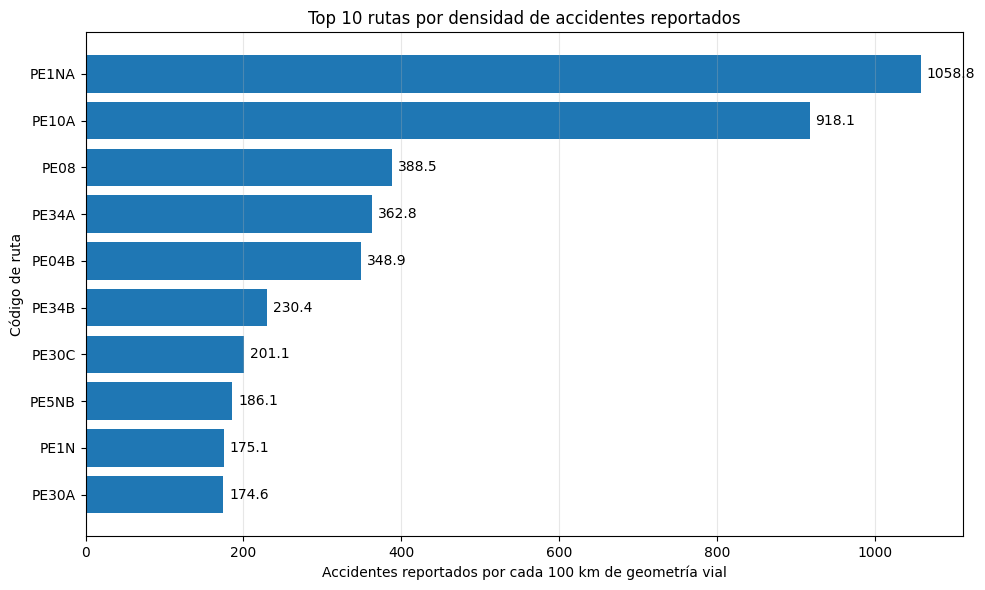

In [12]:
if "cCodRuta" not in capa_vial.columns:
    raise KeyError("No se encontró la columna cCodRuta en la capa vial del MTC.")

# Proyección métrica para estimar longitudes en kilómetros.
vial_metric = capa_vial.to_crs("EPSG:32718").copy()
vial_metric["RUTA_NORMALIZADA"] = vial_metric["cCodRuta"].apply(normalizar_ruta)
vial_metric["LONGITUD_KM"] = vial_metric.geometry.length / 1000

longitudes = (
    vial_metric.loc[vial_metric["RUTA_NORMALIZADA"] != ""]
    .groupby("RUTA_NORMALIZADA", as_index=False)["LONGITUD_KM"]
    .sum()
)

analisis_accidentes = accidentes_ruta.merge(
    longitudes, on="RUTA_NORMALIZADA", how="left"
)
analisis_accidentes = analisis_accidentes.loc[
    analisis_accidentes["LONGITUD_KM"].gt(0)
].copy()
analisis_accidentes["ACCIDENTES_POR_100_KM"] = (
    analisis_accidentes["TOTAL_ACCIDENTES"]
    / analisis_accidentes["LONGITUD_KM"] * 100
)

top_densidad = (
    analisis_accidentes.sort_values("ACCIDENTES_POR_100_KM", ascending=False)
    .head(10).sort_values("ACCIDENTES_POR_100_KM")
)
display(top_densidad[[
    "RUTA_NORMALIZADA", "TOTAL_ACCIDENTES", "LONGITUD_KM", "ACCIDENTES_POR_100_KM"
]])

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(top_densidad["RUTA_NORMALIZADA"], top_densidad["ACCIDENTES_POR_100_KM"])
ax.bar_label(barras, fmt="%.1f", padding=4)
ax.set_title("Top 10 rutas por densidad de accidentes reportados")
ax.set_xlabel("Accidentes reportados por cada 100 km de geometría vial")
ax.set_ylabel("Código de ruta")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Mapa final: rutas con más accidentes reportados

Rutas del top 10 no encontradas en la capa MTC: ['PE022', 'PE03']


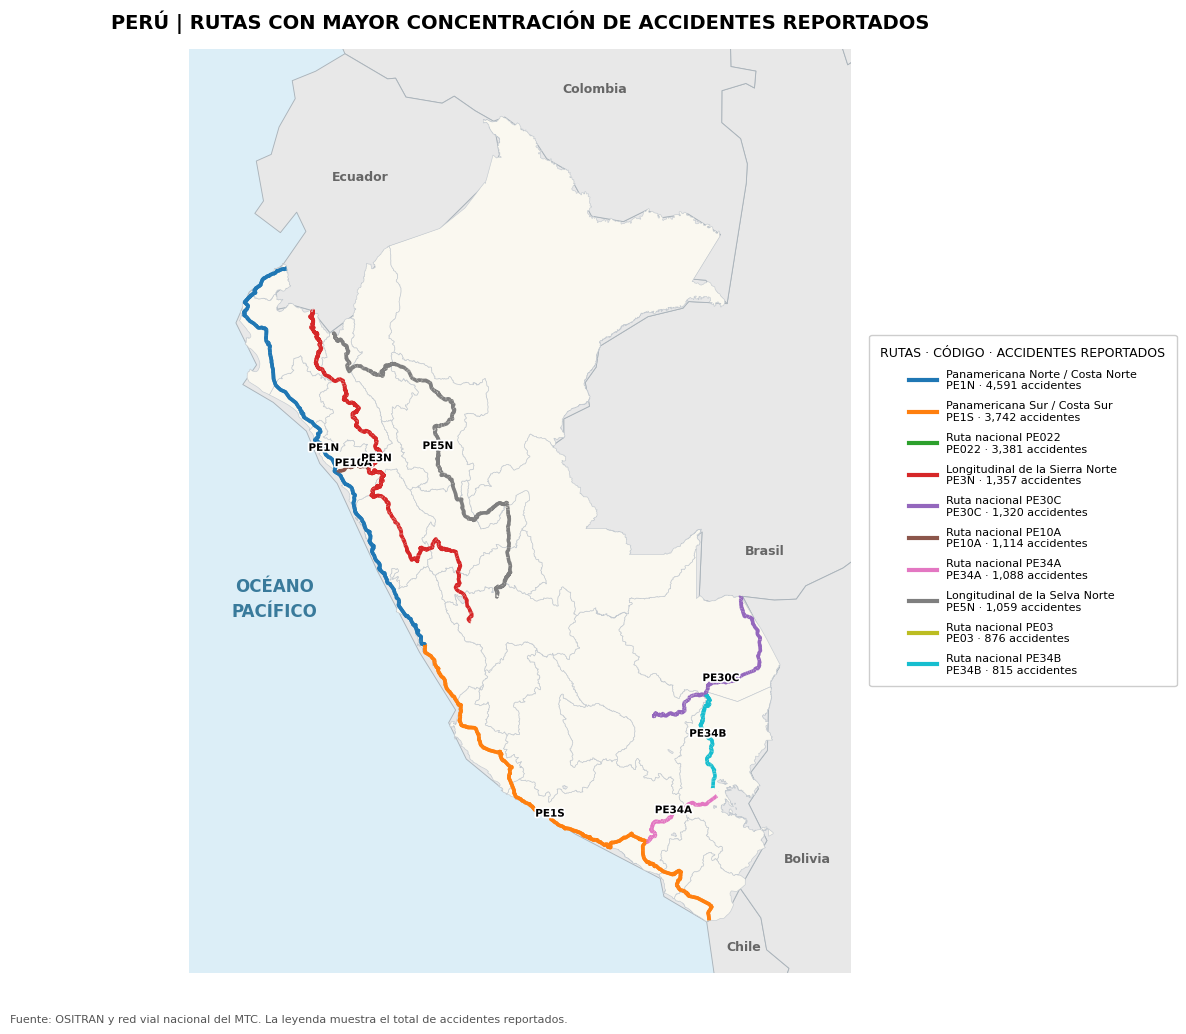

In [13]:
dept = departamentos.to_crs(CRS_MAPA).copy()
world = paises.to_crs(CRS_MAPA).copy()
vial = capa_vial.to_crs(CRS_MAPA).copy()

if "cCodRuta" not in vial.columns:
    raise KeyError("No se encontró cCodRuta en la capa vial del MTC.")
vial["RUTA_NORMALIZADA"] = vial["cCodRuta"].apply(normalizar_ruta)

candidatos_nombre = ["ADMIN", "NAME", "name", "NAME_EN", "SOVEREIGNT", "COUNTRY"]
col_pais = next((c for c in candidatos_nombre if c in world.columns), None)
if col_pais is None:
    raise KeyError(f"No se identificó el nombre de país. Columnas: {world.columns.tolist()}")

nombres_vecinos = {
    normalizar_nombre(n)
    for n in ["Peru", "Ecuador", "Colombia", "Brazil", "Bolivia", "Chile"]
}
paises_mapa = world[world[col_pais].apply(normalizar_nombre).isin(nombres_vecinos)].copy()

top10 = accidentes_ruta.head(10).copy()
codigos_top = top10["RUTA_NORMALIZADA"].tolist()
rutas_mapa = vial[vial["RUTA_NORMALIZADA"].isin(codigos_top)].copy()

faltantes_mtc = set(codigos_top) - set(rutas_mapa["RUTA_NORMALIZADA"].dropna().unique())
if faltantes_mtc:
    print("Rutas del top 10 no encontradas en la capa MTC:", sorted(faltantes_mtc))

paleta = plt.get_cmap("tab10").colors
color_ruta = {codigo: paleta[i % len(paleta)] for i, codigo in enumerate(codigos_top)}

fig, ax = plt.subplots(figsize=(15, 11))
fig.subplots_adjust(left=0.03, right=0.72, top=0.91, bottom=0.07)

# El océano se dibuja primero; las capas terrestres quedan encima.
oceano = gpd.GeoDataFrame(
    {"nombre": ["Océano Pacífico"]},
    geometry=[box(XMIN - 1, YMIN - 1, XMAX + 1, YMAX + 1)],
    crs=CRS_MAPA
)
oceano.plot(ax=ax, color=COLOR_OCEANO, edgecolor="none", zorder=0)
paises_mapa.plot(ax=ax, color="#E8E8E8", edgecolor="#AAB3BA", linewidth=0.65, zorder=1)
dept.plot(ax=ax, color="#FAF8F0", edgecolor="#C5CBD1", linewidth=0.45, zorder=2)

for codigo in codigos_top:
    parte = rutas_mapa[rutas_mapa["RUTA_NORMALIZADA"] == codigo]
    if not parte.empty:
        parte.plot(ax=ax, color=color_ruta[codigo], linewidth=2.6, zorder=4)

# Etiquetas de los códigos de ruta.
rutas_unicas = rutas_mapa.dissolve(by="RUTA_NORMALIZADA")
for codigo, fila in rutas_unicas.iterrows():
    punto = fila.geometry.representative_point()
    ax.annotate(
        codigo, (punto.x, punto.y), fontsize=7.5, fontweight="bold",
        ha="center", color="black", zorder=6,
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")]
    )

etiquetas_paises = {
    "Ecuador": (-78.5, -1.5),
    "Colombia": (-73.0, 0.5),
    "Brasil": (-69.0, -10.0),
    "Bolivia": (-68.0, -17.0),
    "Chile": (-69.5, -19.0),
}
for nombre, (x, y) in etiquetas_paises.items():
    ax.text(x, y, nombre, fontsize=9, color="#666666",
            fontweight="bold", ha="center", zorder=3, clip_on=True)

ax.text(-80.5, -11, "OCÉANO\nPACÍFICO", fontsize=12, fontweight="bold",
        color="#397A9B", ha="center", va="center", linespacing=1.5, zorder=5)

elementos_leyenda = []
for _, fila in top10.iterrows():
    codigo = fila["RUTA_NORMALIZADA"]
    total = int(fila["TOTAL_ACCIDENTES"])
    nombre = NOMBRES_RUTAS.get(codigo, f"Ruta nacional {codigo}")
    elementos_leyenda.append(Line2D(
        [0], [0], color=color_ruta[codigo], linewidth=3,
        label=f"{nombre}\n{codigo} · {total:,} accidentes"
    ))

ax.legend(
    handles=elementos_leyenda,
    title="RUTAS · CÓDIGO · ACCIDENTES REPORTADOS",
    loc="center left", bbox_to_anchor=(1.02, 0.5),
    fontsize=8, title_fontsize=9, frameon=True, framealpha=0.98,
    edgecolor="#CCCCCC", handlelength=2.5, labelspacing=0.9, borderpad=1
)

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)
ax.set_title(
    "PERÚ | RUTAS CON MAYOR CONCENTRACIÓN DE ACCIDENTES REPORTADOS",
    fontsize=14, fontweight="bold", pad=15
)
ax.set_axis_off()
fig.text(
    0.035, 0.025,
    "Fuente: OSITRAN y red vial nacional del MTC. "
    "La leyenda muestra el total de accidentes reportados.",
    fontsize=8, color="#555555"
)

plt.savefig("mapa_accidentes_ositran_limpio.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()

## 6. Exportar tablas de resultados

In [14]:
accidentes_ruta.to_csv("accidentes_por_ruta.csv", index=False, encoding="utf-8-sig")
analisis_accidentes.to_csv("analisis_accidentes_por_100_km.csv", index=False, encoding="utf-8-sig")
print("Exportaciones completadas.")

Exportaciones completadas.
